# Tutorial 0: Introducción a las Imágenes Médicas

En este notebook veremos una breve introducción a los diferentes tipos de imagen en el ámbito médico. Aprenderemos a visualizar y analizar casos de diferentes modalidades de imagen médica utilizados para diagnóstico.

## Las modalidades de imagen médica

Dentro del mundo del diagnóstico por imagen, existen diferentes modalidades. Cada una de ellas utiliza un principio físico diferente que puede ayudar a diferenciar mejor estructuras específicas con mayor precisión. A continuación tenéis una tabla con un resumen de las modalidades más comunes utilizadas para diagnóstico.

| Modalidad | Principio Físico | Principales Usos | Formato/Datos habituales |
| :--- | :--- | :--- | :--- |
| **Rayos X (X-Ray)** | Radiación electromagnética | Detección de fracturas óseas, infecciones pulmonares. | 2D, escala de grises (alta densidad = blanco). |
| **Tomografía Computarizada (TAC / CT)** | Múltiples Rayos X rotatorios | Detección de tumores, hemorragias internas, análisis 3D. | 3D (volúmenes / cortes 2D), Unidades Hounsfield (HU). |
| **Resonancia Magnética (RM / MRI)** | Campos magnéticos y ondas de radio | Tejido blando: cerebro, músculos, ligamentos, médula. | 3D, multitono (múltiples contrastes: T1, T2, FLAIR). |
| **Ecografía (Ultrasonido)** | Ondas sonoras de alta frecuencia | Monitorización de embarazos, flujo sanguíneo, órganos del abdomen. | 2D/3D dinámico (vídeo en tiempo real), suele tener ruido (*speckle*). |



Importamos las librerías y descargamos los datos de las diferentes imágenes médicas. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import nibabel as nib
import skimage

# Configuración de visualización
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['image.cmap'] = 'gray'

Los rayos X son las imágenes más comunes dentro del sistema hospitalario. Se suelen usar para diagnosticar fracturas óseas dentro del circuito de urgencias de los centros médicos de tamaño intermedio hasta hospitales de gran tamaño. Esta modalidad da como resultados imágenes 2D que presentan un gran contraste entre los tejidos duros y los blandos.

Dimensiones de la imagen de Rayos X: (1716, 1636)


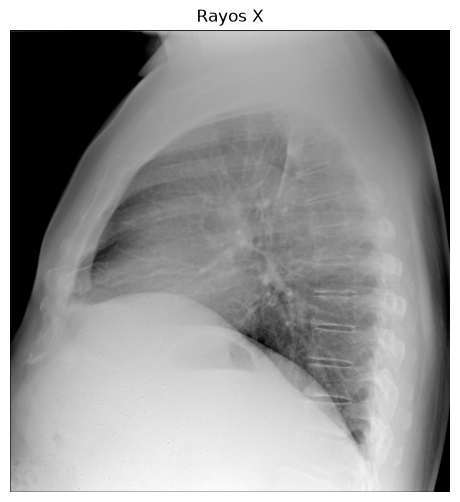

In [2]:
x_ray = plt.imread('data/x_ray.png')  # Carga de imagen de rayos X

# Puedes comprobar que la imagen es 2D
print(f"Dimensiones de la imagen de Rayos X: {x_ray.shape}")

# Visualización de la imagen de rayos X
fig, ax = plt.subplots(1, 1)
ax.imshow(x_ray, cmap='gray')
ax.set_title("Rayos X")
ax.set_axis_off()

> **Pregunta:** ¿Qué órganos se pueden ver en la imagen anterior?

Puede darse el caso de que encontremos algunas de las imágenes médicas en formatos diferentes a los clásicos PNG y JPEG. En este caso, podemos ver un ejemplo de una Resonancia Magnética que la encontramos en formato NIFTI (*Neuroimaging Informatics Technology Initiative*). 

Dimensiones del volumen de Tomografía Computarizada: (10, 256, 256)
Dimensiones del volumen de Resonancia Magnética: (256, 256, 150)


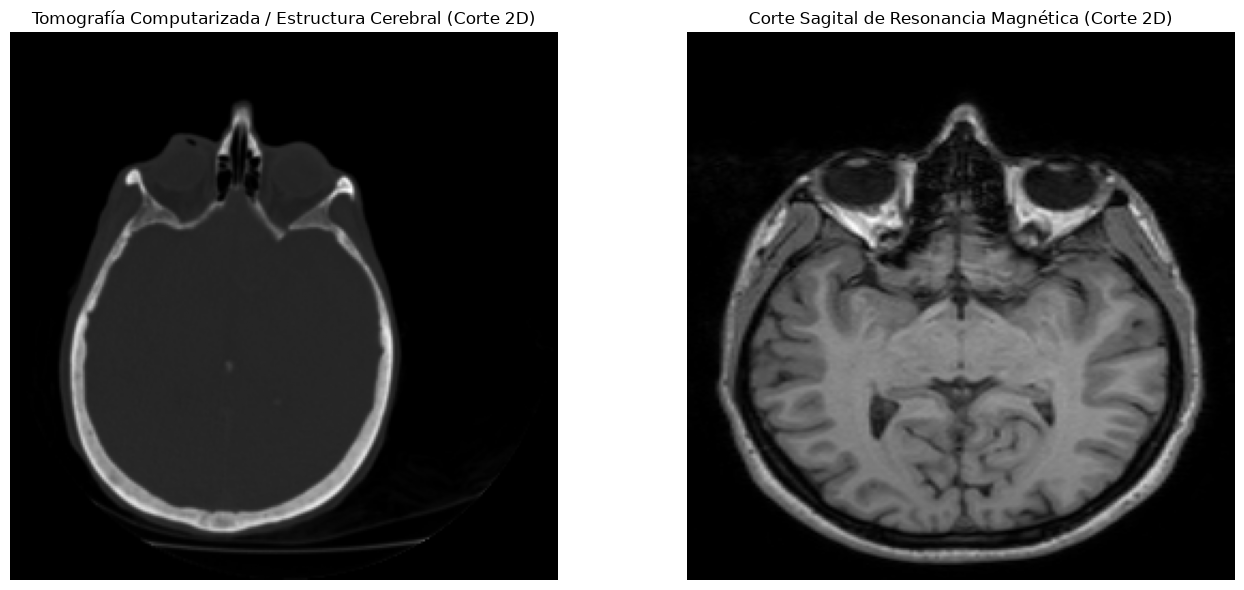

In [4]:
# Carga directa desde la librería sin descargas de URL externas
ct_array = data.brain() # Corte 3D de tomografía/resonancia
mri_filename = "data\\MRI_T1.nii\\IXI002-Guys-0828-MPRAGESEN_-s256_-0301-00003-000001-01.nii"  # Archivo NIFTI de resonancia magnética
mri_img = nib.load(mri_filename)

mri_slice = mri_img.get_fdata()  # Volumen 3D de resonancia magnética

# Se puede comprobar que las imágenes originales son 3D
print(f"Dimensiones del volumen de Tomografía Computarizada: {ct_array.shape}")
# Comprobar que el volumen de resonancia magnética es 2D
print(f"Dimensiones del volumen de Resonancia Magnética: {mri_slice.shape}")

# Extraer un corte 2D central de cada volumen
ct_slice = ct_array[ct_array.shape[0] // 2]
ct_shape = ct_slice.shape
mri_slice = mri_slice[:, mri_slice.shape[1] // 2, :]  # Tomar un corte sagital central

mri_slice = skimage.transform.resize(mri_slice, ct_shape)  # Redimensionar para que coincida con el corte de CT
# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(ct_slice)
axes[0].set_title("Tomografía Computarizada / Estructura Cerebral (Corte 2D)")
axes[0].set_axis_off()

axes[1].imshow(mri_slice)  # Rotar para una mejor visualización
axes[1].set_title("Corte Sagital de Resonancia Magnética (Corte 2D)")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

En las imágenes anteriores podemos ver las diferencias entre ambas modalidades para la detección de tejidos en el cráneo. 

> **Pregunta:** Un paciente llega a urgencias después de un golpe en la cabeza con mareos y náuseas. Tras una exploración inicial el médico de urgencias piensa que podría tratarse de una ruptura de cráneo. ¿Cuál de las dos modalidades de imagen crees que debería pedirse? 

Otra de las modalidades más comunes dentro del ámbito médico son los ultrasonidos. Normalmente, al usar ondas mecánicas se suelen utilizar para obtener imágenes de los bebés neonatos durante el embarazo (*ecografía*).

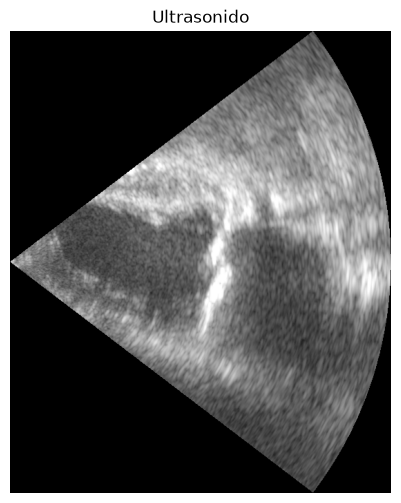

In [6]:
us_img_file = "data\\ultrasound.nii\\ultrasound.nii"  # Archivo de imagen de ultrasonido
us_img = nib.load(us_img_file)
us_slice = us_img.get_fdata()

# Visualización de la imagen de ultrasonido
fig, ax = plt.subplots(1, 1)
ax.imshow(us_slice, cmap='gray')
ax.set_title("Ultrasonido")
ax.set_axis_off()

> **Pregunta:** ¿Qué órgano se ve en la imagen de ultrasonidos?

## Ejemplo práctico desde el punto de vista empresarial: Segmentación de tejidos

Un caso de uso práctico de imágenes médicas desde un punto de vista de ahorro de costes es el uso de técnicas de procesamiento de imagen (veremos algunas de ellas en esta asignatura) para segmentar tejidos específicos de las imágenes. Esto reduce el coste de obtener diferentes imágenes para diferenciar entre tejidos.

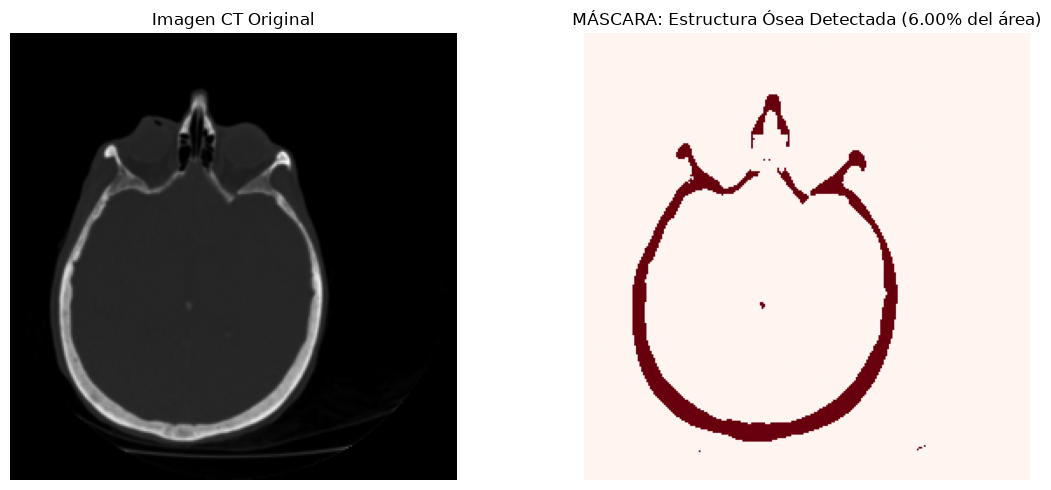

In [7]:
# Umbralización para aislar hueso / tejido denso (Valores > 10000)

umbral_hueso = 10000
mascara_hueso = ct_slice > umbral_hueso

# Porcentaje del área ocupada
porcentaje_ocupado = (np.sum(mascara_hueso) / mascara_hueso.size) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(ct_slice, cmap='gray')
axes[0].set_title("Imagen CT Original")
axes[0].axis('off')

axes[1].imshow(mascara_hueso, cmap='Reds')
axes[1].set_title(f"MÁSCARA: Estructura Ósea Detectada ({porcentaje_ocupado:.2f}% del área)")
axes[1].axis('off')

plt.tight_layout()
plt.show()